In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Tabel Data Hasil Pengujian Komparasi Lengkap 9 Model (Bahan UTS)
hasil_pengujian = [
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 11.19,
        'Silhouette Score': 0.0162,
        'Davies-Bouldin Index (DBI)': 7.2703,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 5.07,
        'Silhouette Score': 0.0166,
        'Davies-Bouldin Index (DBI)': 3.9829,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Agglomerative (Bottom-Up)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 6.92,
        'Silhouette Score': 0.2694,
        'Davies-Bouldin Index (DBI)': 1.2762,
        'Memori (MB)': 74.98
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 0.93,
        'Silhouette Score': 0.0356,
        'Davies-Bouldin Index (DBI)': 8.0441,
        'Memori (MB)': 64.12
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 0.68,
        'Silhouette Score': 0.0233,
        'Davies-Bouldin Index (DBI)': 7.3468,
        'Memori (MB)': 58.11
    },
    {
        'Model': 'Divisive (Top-Down)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 6,
        'Noise': 0,
        'Waktu Eksekusi (s)': 1.27,
        'Silhouette Score': 0.1729,
        'Davies-Bouldin Index (DBI)': 5.7614,
        'Memori (MB)': 94.60
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Cosine',
        'Jumlah Klaster': 6,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 1.38,
        'Silhouette Score': -0.0029,
        'Davies-Bouldin Index (DBI)': 2.2708,
        'Memori (MB)': 332.78
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Euclidean',
        'Jumlah Klaster': 6,
        'Noise': 3540,
        'Waktu Eksekusi (s)': 41.43,
        'Silhouette Score': 0.0006,
        'Davies-Bouldin Index (DBI)': 2.2708,
        'Memori (MB)': 4.06
    },
    {
        'Model': 'HDBSCAN (Density-Based)',
        'Metrik Jarak': 'Manhattan',
        'Jumlah Klaster': 3,
        'Noise': 1122,
        'Waktu Eksekusi (s)': 41.38,
        'Silhouette Score': 0.1599,
        'Davies-Bouldin Index (DBI)': 1.9478,
        'Memori (MB)': 4.06
    }
]

df_perbandingan = pd.DataFrame(hasil_pengujian)
df_perbandingan


,Model,Metrik Jarak,Jumlah Klaster,Noise,Waktu Eksekusi (s),Silhouette Score,Davies-Bouldin Index (DBI),Memori (MB)
0,Agglomerative (Bottom-Up),Cosine,6,0,11.19,0.0162,7.2703,74.98
1,Agglomerative (Bottom-Up),Euclidean,6,0,5.07,0.0166,3.9829,74.98
2,Agglomerative (Bottom-Up),Manhattan,6,0,6.92,0.2694,1.2762,74.98
3,Divisive (Top-Down),Cosine,6,0,0.93,0.0356,8.0441,64.12
4,Divisive (Top-Down),Euclidean,6,0,0.68,0.0233,7.3468,58.11
5,Divisive (Top-Down),Manhattan,6,0,1.27,0.1729,5.7614,94.60
6,HDBSCAN (Density-Based),Cosine,6,3540,1.38,-0.0029,2.2708,332.78
7,HDBSCAN (Density-Based),Euclidean,6,3540,41.43,0.0006,2.2708,4.06
8,HDBSCAN (Density-Based),Manhattan,3,1122,41.38,0.1599,1.9478,4.06


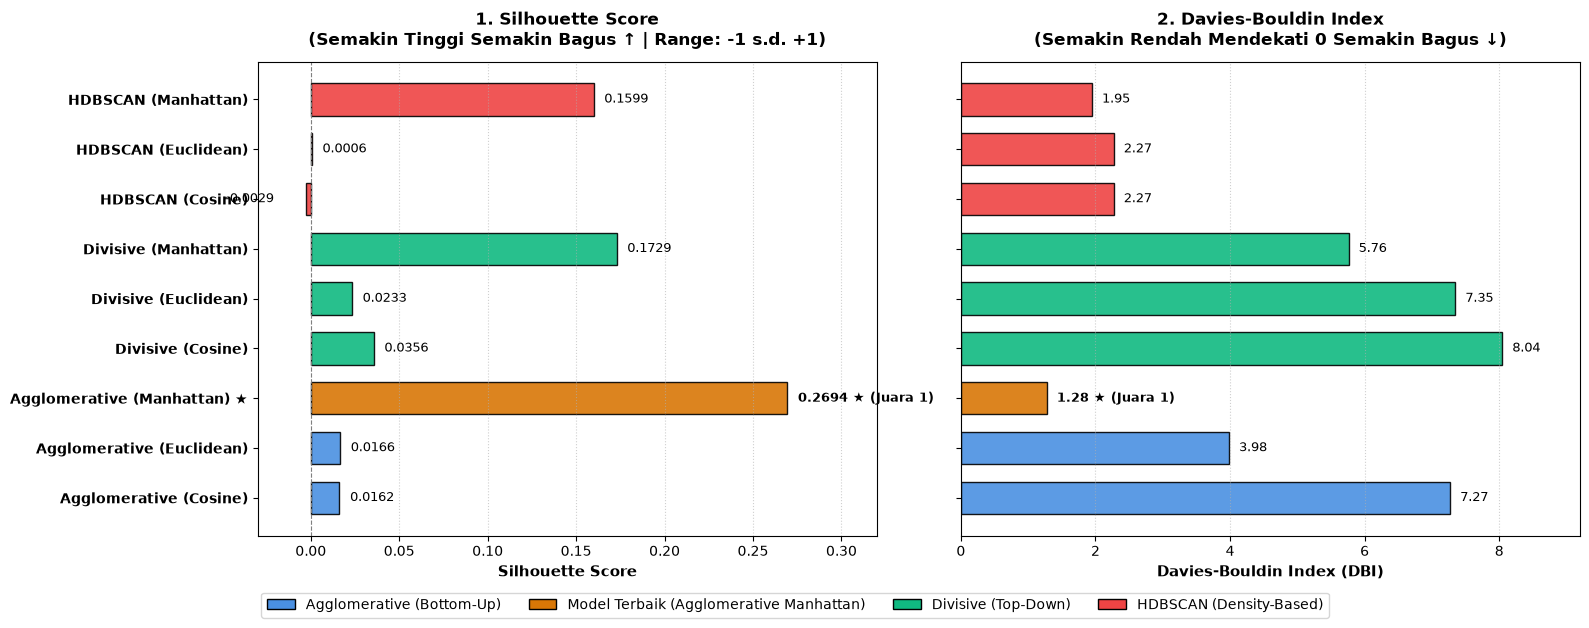

In [2]:
# ==============================================================================
# VISUALISASI 1: EVALUASI KUALITAS KLASTER (SILHOUETTE SCORE & DAVIES-BOULDIN INDEX)
# Menggunakan grafik batang horizontal agar nama model terbaca jelas tanpa tumpang-tindih.
# ==============================================================================

# Label nama model yang rapi dan terstruktur
labels = [
    'Agglomerative (Cosine)',
    'Agglomerative (Euclidean)',
    'Agglomerative (Manhattan) ★',
    'Divisive (Cosine)',
    'Divisive (Euclidean)',
    'Divisive (Manhattan)',
    'HDBSCAN (Cosine)',
    'HDBSCAN (Euclidean)',
    'HDBSCAN (Manhattan)'
]

# Warna tematik berdasarkan rumpun algoritma
# Highlight emas/oranye khusus untuk model terbaik (Agglomerative Manhattan)
warna_agg = ['#4A90E2', '#4A90E2', '#D97706']  # Manhattan di-highlight emas
warna_div = ['#10B981', '#10B981', '#10B981']  # Hijau lembut
warna_hdb = ['#EF4444', '#EF4444', '#EF4444']  # Merah lembut
palette = warna_agg + warna_div + warna_hdb

# Balik urutan agar model teratas muncul di paling atas grafik
y_pos = np.arange(len(labels))[::-1]
labels_plot = labels[::-1]
palette_plot = palette[::-1]

sil_scores = df_perbandingan['Silhouette Score'].values[::-1]
dbi_scores = df_perbandingan['Davies-Bouldin Index (DBI)'].values[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- GRAFIK 1: Silhouette Score (Semakin Tinggi Semakin Baik ↑) ---
bars1 = ax1.barh(y_pos, sil_scores, color=palette_plot, edgecolor='black', height=0.65, alpha=0.9)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(labels_plot, fontsize=10, fontweight='bold')
ax1.axvline(0, color='grey', linestyle='--', linewidth=0.8)
ax1.set_xlabel('Silhouette Score', fontsize=11, fontweight='bold')
ax1.set_title('1. Silhouette Score\n(Semakin Tinggi Semakin Bagus ↑ | Range: -1 s.d. +1)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlim(-0.03, 0.32)
ax1.grid(axis='x', linestyle=':', alpha=0.6)

# Anotasi angka di ujung batang
for bar, val in zip(bars1, sil_scores):
    w = bar.get_width()
    offset = 0.006 if w >= 0 else -0.018
    bold_weight = 'bold' if val == max(sil_scores) else 'normal'
    star = ' ★ (Juara 1)' if val == max(sil_scores) else ''
    ax1.text(w + offset, bar.get_y() + bar.get_height()/2., f'{val:.4f}{star}',
             va='center', ha='left' if w >= 0 else 'right', fontsize=9, fontweight=bold_weight)

# --- GRAFIK 2: Davies-Bouldin Index (Semakin Rendah Semakin Baik ↓) ---
bars2 = ax2.barh(y_pos, dbi_scores, color=palette_plot, edgecolor='black', height=0.65, alpha=0.9)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([]) # Sembunyikan label y agar tidak repetitif
ax2.set_xlabel('Davies-Bouldin Index (DBI)', fontsize=11, fontweight='bold')
ax2.set_title('2. Davies-Bouldin Index\n(Semakin Rendah Mendekati 0 Semakin Bagus ↓)', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlim(0, 9.2)
ax2.grid(axis='x', linestyle=':', alpha=0.6)

for bar, val in zip(bars2, dbi_scores):
    w = bar.get_width()
    bold_weight = 'bold' if val == min(dbi_scores) else 'normal'
    star = ' ★ (Juara 1)' if val == min(dbi_scores) else ''
    ax2.text(w + 0.15, bar.get_y() + bar.get_height()/2., f'{val:.2f}{star}',
             va='center', ha='left', fontsize=9, fontweight=bold_weight)

# Legenda Rumpun Model
from matplotlib.patches import Patch
legend_items = [
    Patch(facecolor='#4A90E2', edgecolor='black', label='Agglomerative (Bottom-Up)'),
    Patch(facecolor='#D97706', edgecolor='black', label='Model Terbaik (Agglomerative Manhattan)'),
    Patch(facecolor='#10B981', edgecolor='black', label='Divisive (Top-Down)'),
    Patch(facecolor='#EF4444', edgecolor='black', label='HDBSCAN (Density-Based)')
]
fig.legend(handles=legend_items, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.05), fontsize=10)

plt.tight_layout()
plt.show()


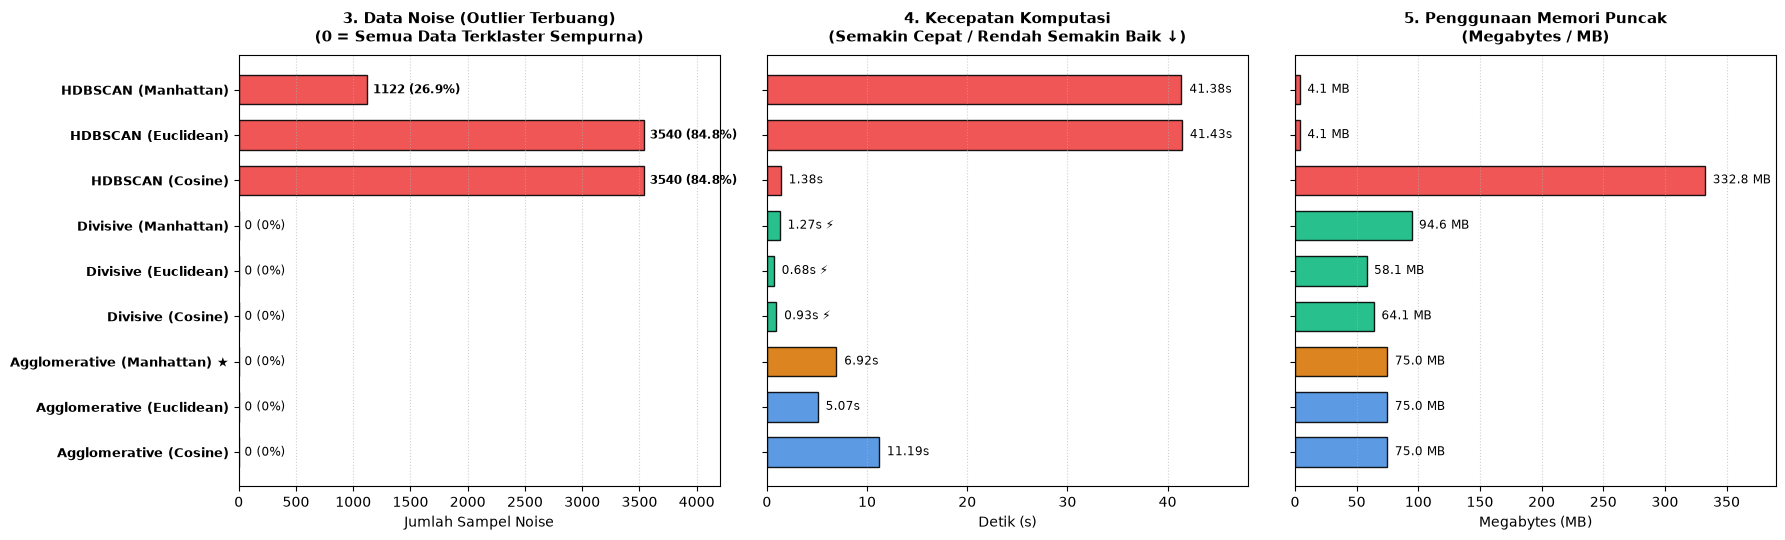

In [3]:
# ==============================================================================
# VISUALISASI 2: EFISIENSI SISTEM & KARAKTERISTIK DATA (NOISE, WAKTU, MEMORI)
# ==============================================================================

fig, (ax_noise, ax_waktu, ax_mem) = plt.subplots(1, 3, figsize=(18, 5.5))

noise_vals = df_perbandingan['Noise'].values[::-1]
waktu_vals = df_perbandingan['Waktu Eksekusi (s)'].values[::-1]
mem_vals = df_perbandingan['Memori (MB)'].values[::-1]

# 1. Noise Data (Outlier Terbuang)
bars_n = ax_noise.barh(y_pos, noise_vals, color=palette_plot, edgecolor='black', height=0.65, alpha=0.9)
ax_noise.set_yticks(y_pos)
ax_noise.set_yticklabels(labels_plot, fontsize=9.5, fontweight='bold')
ax_noise.set_title('3. Data Noise (Outlier Terbuang)\n(0 = Semua Data Terklaster Sempurna)', fontsize=11, fontweight='bold', pad=10)
ax_noise.set_xlabel('Jumlah Sampel Noise')
ax_noise.set_xlim(0, 4200)
ax_noise.grid(axis='x', linestyle=':', alpha=0.6)
for bar, val in zip(bars_n, noise_vals):
    w = bar.get_width()
    pct = f' ({val/4176*100:.1f}%)' if val > 0 else ' (0%)'
    ax_noise.text(w + 50, bar.get_y() + bar.get_height()/2., f'{int(val)}{pct}',
                 va='center', ha='left', fontsize=8.5, fontweight='bold' if val > 0 else 'normal')

# 2. Waktu Eksekusi (Detik)
bars_w = ax_waktu.barh(y_pos, waktu_vals, color=palette_plot, edgecolor='black', height=0.65, alpha=0.9)
ax_waktu.set_yticks(y_pos)
ax_waktu.set_yticklabels([])
ax_waktu.set_title('4. Kecepatan Komputasi\n(Semakin Cepat / Rendah Semakin Baik ↓)', fontsize=11, fontweight='bold', pad=10)
ax_waktu.set_xlabel('Detik (s)')
ax_waktu.set_xlim(0, 48)
ax_waktu.grid(axis='x', linestyle=':', alpha=0.6)
for bar, val in zip(bars_w, waktu_vals):
    w = bar.get_width()
    star = ' ⚡' if val <= 1.3 else ''
    ax_waktu.text(w + 0.8, bar.get_y() + bar.get_height()/2., f'{val:.2f}s{star}',
                 va='center', ha='left', fontsize=8.5)

# 3. Penggunaan Memori (MB)
bars_m = ax_mem.barh(y_pos, mem_vals, color=palette_plot, edgecolor='black', height=0.65, alpha=0.9)
ax_mem.set_yticks(y_pos)
ax_mem.set_yticklabels([])
ax_mem.set_title('5. Penggunaan Memori Puncak\n(Megabytes / MB)', fontsize=11, fontweight='bold', pad=10)
ax_mem.set_xlabel('Megabytes (MB)')
ax_mem.set_xlim(0, 390)
ax_mem.grid(axis='x', linestyle=':', alpha=0.6)
for bar, val in zip(bars_m, mem_vals):
    w = bar.get_width()
    ax_mem.text(w + 6, bar.get_y() + bar.get_height()/2., f'{val:.1f} MB',
                 va='center', ha='left', fontsize=8.5)

plt.tight_layout()
plt.show()


### 🎓 PANDUAN RINGKAS MENJAWAB UJIAN UTS (CHEAT-SHEET CLUSTERING)

---

#### 🏆 1. Model Mana yang Menjadi Juara 1?
> **Jawab:** **Hierarchical Agglomerative Clustering dengan Jarak Manhattan ($K=6$)**.
- **Bukti 1 (Silhouette Score)**: Meraih skor **0.2694** (tertinggi mutlak di antara seluruh 9 model).
- **Bukti 2 (Davies-Bouldin Index)**: Meraih indeks **1.2762** (terendah/terbaik, membuktikan klaster padat di dalam dan terpisah tegas antarklaster).
- **Bukti 3 (Noise Zero)**: Seluruh **4.176 artikel hoaks** 100% berhasil dikelompokkan ke dalam topik tanpa ada data yang terbuang.

---

#### ⚡ 2. Apa Keunggulan Divisive (Top-Down) Dibanding Agglomerative (Bottom-Up)?
> **Jawab:** **Kecepatan Komputasi (Scalability)**.
- **Divisive hanya butuh 0.68 – 1.27 detik**, sedangkan Agglomerative butuh **5.07 – 11.19 detik** (Divisive ~10x lebih cepat).
- *Alasan Matematika*: Divisive hanya memotong klaster terbesar secara biseksi lokal hingga mencapai $K=6$ ($O(K \cdot N \cdot d)$), sedangkan Agglomerative harus menghitung seluruh matriks jarak berpasangan $N 	imes N$ ($O(N^2)$).
- **Divisive Manhattan** tetap menghasilkan pemisahan yang sangat bagus (Silhouette: **0.1729**).

---

#### 📏 3. Mengapa Jarak Manhattan Selalu Menang Mengalahkan Euclidean & Cosine?
> **Jawab:** **Karena Terhindar dari *Curse of Dimensionality***.
- Matriks representasi teks (TF-IDF 1.000 kata) memiliki ruang dimensi sangat tinggi dan sangat kosong (*sparse*).
- **Jarak Euclidean** mengkuadratkan selisih $(x_i - y_i)^2$. Pada dimensi tinggi yang kosong, pengkuadratan ini menekan nilai kecil mendekati nol sehingga jarak antar-dokumen menjadi seragam (*distance concentration*).
- **Jarak Manhattan (L1-norm)** menjumlahkan selisih absolut secara linear $|x_i - y_i|$, sehingga perbedaan frekuensi kata-kata kunci tetap tajam dan diskriminatif.

---

#### ⚠️ 4. Mengapa HDBSCAN Gagal Total pada Dataset Berita Ini?
> **Jawab:** **Karena HDBSCAN adalah Algoritma Berbasis Densitas (Kepadatan)**.
- Pada jarak Cosine dan Euclidean, HDBSCAN membuang **3.540 dari 4.176 berita (84.77%)** sebagai *noise/outlier*.
- Pada ruang teks berdimensi tinggi, dokumen tersebar berjauhan sehingga kerapatan titik data sangat rendah. Akibatnya, sebagian besar berita tidak memenuhi ambang batas densitas minimum (*min_samples*) dan langsung dibuang.

---

#### ❓ 5. Apakah Unsupervised Clustering Ini Sudah Bisa Menentukan "Berita Ini Hoaks atau Fakta"?
> **Jawab:** **BELUM BISA**.
- Unsupervised learning hanya mengelompokkan teks berdasarkan **kemiripan topik kata** (misal: klaster isu politik pemilu, klaster penipuan finansial/bansos, klaster kesehatan).
- Model tidak memiliki label kebenaran fakta ("apakah berita ini benar atau palsu").
- **Solusi Lanjutan**: Untuk membuat sistem deteksi hoaks yang valid, dibutuhkan pendekatan **Supervised Learning** (klasifikasi dengan label *Hoaks vs Valid*).
